### 1. Introducción y Preparación de Datos (`melbourne_limpio.csv`)

####  1.1. ¿De dónde partimos?
Para que todo el equipo trabaje bajo las mismas reglas, hemos partido del dataset original (`Melbourne_housing_FULL.csv`) y hemos generado un único archivo limpio: **`melbourne_limpio.csv`**.

Este archivo contiene **15 columnas finales y 0 valores nulos**.

---
####  1.2. ¿Cómo se han tratado los datos y los nulos?

En lugar de borrar filas o rellenar huecos con medias globales, hemos seguido un criterio muy lógico en tres pasos:

1. **Limpieza de errores y datos imposibles**:
   * Eliminamos las filas sin precio (`Price`) o sin distancia al centro (`Distance`).
   * Corregimos o borramos datos sin sentido (casas con 0 baños, parcelas o metros construidos con valor 0 o ridículamente gigantes, y años de construcción imposibles).

2. **Imputación inteligente por grupos (Relleno de huecos)**:
   * **El problema de la media general**: Si a un piso pequeño le ponemos los metros construidos medios de todo Melbourne (mezclando mansiones con apartamentos), destruimos la realidad de los datos.
   * **La solución**: Rellenamos los huecos usando la **mediana del grupo más parecido**. Por ejemplo, a una casa de 3 habitaciones sin metros construidos le asignamos la mediana de las casas de 3 habitaciones de su mismo barrio.

3. **Las columnas "Chivato" (`*_imputado`)**:
   * Creamos 3 columnas binarias (`BuildingArea_imputado`, `Landsize_imputado`, `Bathroom_imputado`).
   * Ponen un `1` si el dato lo hemos tenido que estimar nosotros, o un `0` si el dato venía real en el anuncio.
   * **¿Para qué sirven?**: Le enseñan al modelo qué datos son reales y qué datos son estimados. Además, nos servirán para filtrar solo casas reales cuando evaluemos terrenos sin construir (pregunta 1.4).
---
####  1.3. Resumen de las 15 Columnas del Dataset
| Nombre Columna | Tipo | ¿Qué representa? |
| :--- | :--- | :--- |
| **`Price`** | Numérica | **Target**: Precio de venta final de la vivienda ($AUD). |
| **`Rooms`** | Numérica | Número de habitaciones. |
| **`Bathroom`** | Numérica | Número de cuartos de baño. |
| **`Car`** | Numérica | Plazas de garaje. |
| **`Landsize`** | Numérica | Superficie del terreno/parcela ($m^2$). |
| **`BuildingArea`** | Numérica | Superficie construida de la casa ($m^2$). |
| **`YearBuilt`** | Numérica | Año de construcción. |
| **`Distance`** | Numérica | Distancia en km al centro de Melbourne. |
| **`BuildingArea_imputado`** | Binaria (0/1) | Chivato: 1 si rellenamos el área construida, 0 si era real. |
| **`Landsize_imputado`** | Binaria (0/1) | Chivato: 1 si rellenamos el terreno, 0 si era real. |
| **`Bathroom_imputado`** | Binaria (0/1) | Chivato: 1 si rellenamos los baños, 0 si era real. |
| **`Type`** | Texto (Categórica) | Tipo de vivienda (`h` = casa, `u` = piso, `t` = adosado). |
| **`Suburb`** | Texto (Categórica) | Nombre del barrio. |
| **`Method`** | Texto (Categórica) | Método de venta (subasta, venta normal, etc.). |
| **`SellerG`** | Texto (Categórica) | Nombre de la inmobiliaria. |
---
####  1.4. ¿Por qué mi parte (CatBoost) es diferente a la de mis compañeros?
* **Regresión Lineal y Random Forest (Compañeros)**: No pueden leer palabras directas como `"Abbotsford"`. Han tenido que transformar el texto a números o crear decenas de columnas de ceros y unos (`get_dummies`).
* **CatBoost (Mi modelo)**: Entiende el texto directamente. Le pasamos las 4 columnas de texto (`Type`, `Suburb`, `Method`, `SellerG`) tal cual vienen en la tabla, indicándole únicamente en qué posición están para que las procese con su motor interno.
---


# 2. Preguntas de Negocio y Objetivos del Proyecto

---
### 2.1. Validación Cruzada y Capacidad Predictiva
* **Pregunta**: ¿Podemos predecir el precio de una vivienda en Melbourne con una precisión razonable mediante CatBoost y validación cruzada ($k$-fold)?
* **Plan de acción**:
  * Implementaremos una **Validación Cruzada de 5 particiones ($k=5$)**.
  * Evaluaremos el rendimiento en cada iteración calculando **RMSE** (Error Cuadrático Medio), **MAE** (Error Absoluto Medio) y **$R^2$** (Coeficiente de Determinación).
  * Calcularemos la media y desviación estándar de las métricas para comprobar si el rendimiento del modelo es estable o varía por el azar entre particiones.
  * *Resultado esperado*: Disponer de métricas objetivas para comparar nuestro CatBoost frente a la Regresión Lineal y el Random Forest de nuestros compañeros.

---
### 2.2. Importancia de Variables (*Feature Importance*)
* **Pregunta**: ¿Qué características encarecen o devalúan una vivienda según CatBoost?
* **Plan de acción**:
  * Extraeremos el **Feature Importance** nativo de CatBoost para medir el porcentaje de influencia de cada variable.
  * Analizaremos si las variables espaciales y físicas (superficie, número de habitaciones, distancia al centro, barrio, antigüedad) dominan el precio.
  * *Resultado esperado*: Una tabla comparativa y un gráfico de barras para poner en común con las importancias y coeficientes de los modelos del resto del equipo.

---
### 2.3. Indicador Proxy de "Beneficio" por Tipo de Inmueble
* **Pregunta**: ¿Qué tipo de vivienda (`h` = casa, `u` = piso/unidad, `t` = adosado) resulta más beneficiosa?
* **Plan de acción**:
  * Como el dataset no incluye costes de compra/construcción originales, definiremos un **indicador proxy de beneficio**:
    $$\text{Beneficio Proxy} = \frac{\text{Precio Predicho}}{\text{BuildingArea}}$$
    *(Precio predicho por $m^2$ construido, controlado por ubicación y antigüedad).*
  * Analizaremos qué tipología obtiene el mayor valor por $m^2$ según las predicciones de CatBoost.

---
### 2.4. Valoración y Rentabilidad de Terrenos Sin Construir
* **Pregunta**: ¿Es rentable adquirir un terreno vacante sin construir para edificar?
* **Plan de acción**:
  * **Paso A**: Entrenaremos nuestro modelo únicamente con las viviendas reales que sí tienen superficie construida (filtrando `BuildingArea_imputado == 0`).
  * **Paso B**: Estimaremos el precio final que tendría una vivienda hipotética construida sobre las parcelas vacías a partir de su superficie de parcela (`Landsize`), barrio y distancia al centro.
  * **Paso C**: Estableceremos supuestos explícitos de costes medios de construcción por $m^2$ en Melbourne para calcular el margen neto estimado ($\text{Precio Estimado} - \text{Coste Terreno} - \text{Coste Construcción}$) y determinar si la inversión es rentable.

---

### 2.1. Validación Cruzada y Capacidad Predictiva

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

#---------------------------------------preparamos-datos---------------------------------------

# 1. Definir la ruta dinámica al dataset limpio desde PRJ/models/
# Path().resolve() apunta a la carpeta 'models'. Su '.parent' es la carpeta 'PRJ'.
ROOT = Path().resolve().parent if Path().resolve().name == "models" else Path().resolve()
DATA_PATH = ROOT / "datasets" / "melbourne_limpio.csv"


# 2. Cargar el dataset
df = pd.read_csv(DATA_PATH)

# 3. Definir la variable objetivo y las variables categóricas
TARGET = "Price" #creamos variable de texto con el nombre de la columna que prediciremos
CAT_FEATURES = ["Type", "Suburb", "Method", "SellerG"] #creamos una lista con los nombres exactos de las 4 columnas que contienen palabras

# 4. Separar la matriz de características (X) y el objetivo (y)
X = df.drop(columns=[TARGET]) #creamos la columna eliminando la variable target, contiene las 14 columnas 
y = df[TARGET] #guarda los precios reales que el modelo debe aprender 


# Confirmación por pantalla
print("=" * 65)
print("  ESTADO DE LA CARGA DE DATOS")
print("=" * 65)
print(f"  Archivo cargado       : {DATA_PATH.name}")
print(f"  Dimensiones de X      : {X.shape[0]:,} filas x {X.shape[1]} columnas")
print(f"  Variables categóricas : {', '.join(CAT_FEATURES)}")
print("=" * 65 + "\n")


#---------------------------------------dividimos-datos-entreno---------------------------------------

# 1. Configurar K-Fold con 5 particiones aleatorias pero reproducibles
kf = KFold(n_splits=5, shuffle=True, random_state=42)
#hacemos 5 grupos diferentes

# 2. Listas para guardar las métricas calculadas en cada uno de los 5 folds
rmse_scores = []
mae_scores = []
r2_scores = []
feature_importances_list = [] #Guardará el peso de las variables de cada uno de los 5 folds
#listas vacias donde guardaremos las metricas

# Vector para guardar las predicciones Out-Of-Fold de todo el dataset
oof_preds = np.zeros(len(df)) #con esta linea creamos llena de zeros con 27.246 posiciones, una por cada casa 

print("Iniciando Validación Cruzada (5-Fold) con CatBoost...\n")

# 3. Bucle principal de validación cruzada
for fold, (train_idx, val_idx) in enumerate(kf.split(X, y), start=1): # generamos las 5 parejas y cada una 80% y 20% 
    # Separar datos en entrenamiento (80%) y validación (20%) para este fold
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx] 
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx] 

# dividimos bloque de entrenamiento y bloque de validacion


    # Instanciar el modelo CatBoost con hiperparámetros estándar
    model = CatBoostRegressor(
        iterations=500, # 500 arboles
        learning_rate=0.08, #el ritmo que tendra, cada arbol corrige un 8%
        depth=6, #profundidad de 6 por arbol
        loss_function="RMSE",
        random_seed=42,
        verbose=0  # Mantiene la pantalla limpia ocultando el progreso árbol por árbol
    )

    # Entrenar el modelo pasándole las variables categóricas
    model.fit(X_train, y_train, cat_features=CAT_FEATURES)
    #entrenamos el modelo, le especificmaos las que son de texto para que aplique su algortimos interno

    # Predecir sobre las viviendas del bloque de validación

    preds = model.predict(X_val)# le pasamos las 14 cracteristicas de las casas del 20% sin precios
    # Guardar las predicciones de este 20% en su posición real del dataset

    oof_preds[val_idx] = preds #en la ronda 1 del kfold esta examina 20% (5.449 casas) de las casa y saca las predicciones, coge esos 5.449 predicciones y los guarda exactamente en las filas correcpondientes 
    #val_index dentro de la libreria que creamos antes, en la ronda 5 la libreta oof_preds habra rellenado el 100% de las casas 

    

    # Calcular métricas del fold actual
    rmse = np.sqrt(mean_squared_error(y_val, preds)) #compara precios reales con los predichos rmse
    mae = mean_absolute_error(y_val, preds) #compara la diferencia absoluta directa entre lo predich y realidad
    r2 = r2_score(y_val, preds) #compara la precision del modelo frente a una prediccion basica de la media 

    # Guardar métricas en las listas acumuladoras
    rmse_scores.append(rmse)
    mae_scores.append(mae)
    r2_scores.append(r2)
    feature_importances_list.append(model.get_feature_importance())  #nos devuelve un listado con el porcentaje por columa, en total suman un 100% 

    print(f"  [Fold {fold}/5] RMSE: ${rmse:>10,.2f} | MAE: ${mae:>9,.2f} | R2: {r2:.4f}")

# 4. Mostrar resumen global de resultados
print("\n" + "=" * 65)
print("     RESULTADOS GLOBALES DE CATBOOST (MEDIA +/- DESVIACION ESTANDAR)")
print("=" * 65)
print(f"  RMSE Medio : ${np.mean(rmse_scores):>10,.2f}  ( +/- ${np.std(rmse_scores):,.2f} )")
print(f"  MAE Medio  : ${np.mean(mae_scores):>10,.2f}  ( +/- ${np.std(mae_scores):,.2f} )")
print(f"  R2 Medio   : {np.mean(r2_scores):>11.4f}  ( +/- {np.std(r2_scores):.4f} )")
print("=" * 65)

  ESTADO DE LA CARGA DE DATOS
  Archivo cargado       : melbourne_limpio.csv
  Dimensiones de X      : 27,246 filas x 14 columnas
  Variables categóricas : Type, Suburb, Method, SellerG

Iniciando Validación Cruzada (5-Fold) con CatBoost...

  [Fold 1/5] RMSE: $269,800.18 | MAE: $164,562.56 | R2: 0.8149
  [Fold 2/5] RMSE: $297,951.54 | MAE: $168,864.00 | R2: 0.7644
  [Fold 3/5] RMSE: $321,349.48 | MAE: $176,808.10 | R2: 0.7700
  [Fold 4/5] RMSE: $290,665.53 | MAE: $171,916.90 | R2: 0.8011
  [Fold 5/5] RMSE: $285,563.54 | MAE: $170,136.44 | R2: 0.8027

     RESULTADOS GLOBALES DE CATBOOST (MEDIA +/- DESVIACION ESTANDAR)
  RMSE Medio : $293,066.05  ( +/- $16,894.80 )
  MAE Medio  : $170,457.60  ( +/- $3,996.31 )
  R2 Medio   :      0.7906  ( +/- 0.0198 )


### 2.1. Conclusiones y Análisis de Capacidad Predictiva (CatBoost)

A partir de los resultados obtenidos mediante la **Validación Cruzada de 5 particiones ($k=5$)**, respondemos a la pregunta del punto 2.1:

#### 1. Capacidad Explicativa del Mercado ($R^2 = 0.7906 \pm 0.0198$)
* El modelo CatBoost logra explicar el **79.1 % de la variabilidad del precio** de las viviendas en Melbourne utilizando las 14 características seleccionadas.
* La **desviación estándar del $R^2$ ($\pm 0.0198$) es extremadamente baja**, lo que demuestra que el modelo es estable y que su rendimiento no depende del azar ni de cómo se dividan las particiones.

#### 2. Interpretación de los Errores Monetarios
* **MAE (Error Absoluto Medio = $170,457.60 \pm $3,996.31)**:
  En promedio, las predicciones del modelo se desvían **$170,457.60 AUD** del precio real de la vivienda. La baja desviación entre folds ($\pm \$3,996$) confirma una precisión consistente en todo el dataset.
* **RMSE (Raíz del Error Cuadrático Medio = $293,066.05 \pm $16,894.80)**:
  El RMSE es superior al MAE debido a que eleva los errores al cuadrado antes de promediar. Esto significa que existen **viviendas atípicas o de muy alto valor (mansiones)** en el mercado de Melbourne donde el modelo comete desviaciones más elevadas, penalizando la métrica.

#### 3. Veredicto para la Defensa
**Sí, podemos predecir el precio con una precisión razonable.** El modelo CatBoost demuestra una robustez alta sin signos de sobreajuste (*overfitting*), sirviendo como un candidato de alto rendimiento para comparar frente a la Regresión Lineal y el Random Forest del equipo.

---------------------------------------------------------------------------------------

### 2.2. Importancia de Variables (*Feature Importance*)

     IMPORTANCIA MEDIA DE VARIABLES EN CATBOOST (5-FOLD CV)
   1. BuildingArea              :  15.90 %
   2. Suburb                    :  15.85 %
   3. YearBuilt                 :  13.52 %
   4. Distance                  :  12.65 %
   5. Landsize                  :   9.09 %
   6. Type                      :   8.41 %
   7. Bathroom                  :   7.06 %
   8. SellerG                   :   7.00 %
   9. Rooms                     :   6.13 %
  10. Car                       :   1.62 %
  11. Method                    :   1.09 %
  12. Bathroom_imputado         :   0.71 %
  13. Landsize_imputado         :   0.67 %
  14. BuildingArea_imputado     :   0.31 %


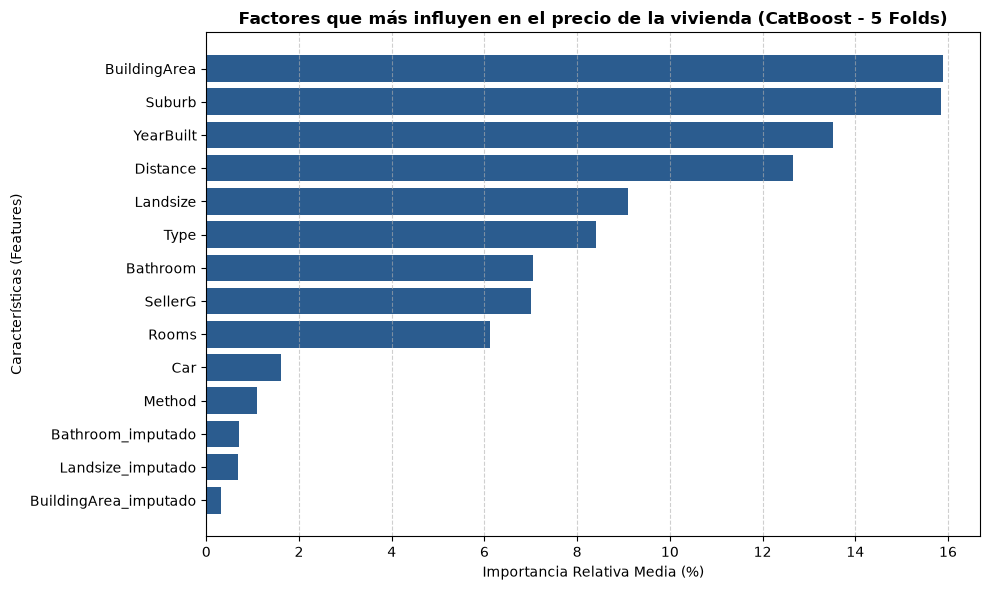

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

#---------------------------------------2.2-importancia-variables---------------------------------------

# 1. Calcular el porcentaje medio de importancia promediando los 5 folds del 2.1
mean_importances = np.mean(feature_importances_list, axis=0) #hacemos la media de los 5 modelos entrenados

# 2. Crear una tabla pandas ordenada de mayor a menor importancia
df_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": mean_importances
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

# 3. Imprimir por pantalla la tabla en texto plano alineada
print("=" * 65)
print("     IMPORTANCIA MEDIA DE VARIABLES EN CATBOOST (5-FOLD CV)")
print("=" * 65)
for idx, row in df_importance.iterrows():
    print(f"  {idx+1:>2}. {row['Feature']:<25} : {row['Importance']:>6.2f} %")
print("=" * 65)

# 4. Generar el gráfico de barras horizontal
plt.figure(figsize=(10, 6))
plt.barh(df_importance["Feature"][::-1], df_importance["Importance"][::-1], color="#2b5c8f")
plt.xlabel("Importancia Relativa Media (%)")
plt.ylabel("Características (Features)")
plt.title("Factores que más influyen en el precio de la vivienda (CatBoost - 5 Folds)", fontsize=12, fontweight="bold")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### 2.2. Conclusiones: Importancia de Variables (CatBoost)

* **Top 4 Variables (58 % del impacto total)**:
  1. **`BuildingArea` (15.90 %)**: Superficie construida real (factor principal del precio).
  2. **`Suburb` (15.85 %)**: Barrio de la vivienda. CatBoost destaca al procesarlo directamente como texto.
  3. **`YearBuilt` (13.52 %)**: Antigüedad de la construcción.
  4. **`Distance` (12.65 %)**: Distancia en km al centro (CBD).

* **Impacto por Bloques**: La ubicación geográfica (`Suburb` + `Distance`) representa casi un **29 %** del precio, y el tamaño del inmueble (`BuildingArea` + `Landsize`) un **25 %**.

* **Validación del Preprocesado**: Las 3 variables chivato (`*_imputado`) suman en conjunto **menos del 1.7 %**, lo que demuestra que la imputación de nulos no metió ruido ni sesgo al modelo.

---

### 2.3. Indicador Proxy de "Beneficio" por Tipo de Inmueble

     INDICADOR DE BENEFICIO PROXY ($ / m2 CONSTRUIDO)
  Piso / Unidad (u)    | Mediana: $7,964.19/m² | Media: $8,920.76/m² | N = 5,909
  Casa (h)             | Mediana: $7,540.50/m² | Media: $8,831.78/m² | N = 18,471
  Adosado (t)          | Mediana: $6,565.75/m² | Media: $10,500.45/m² | N = 2,866


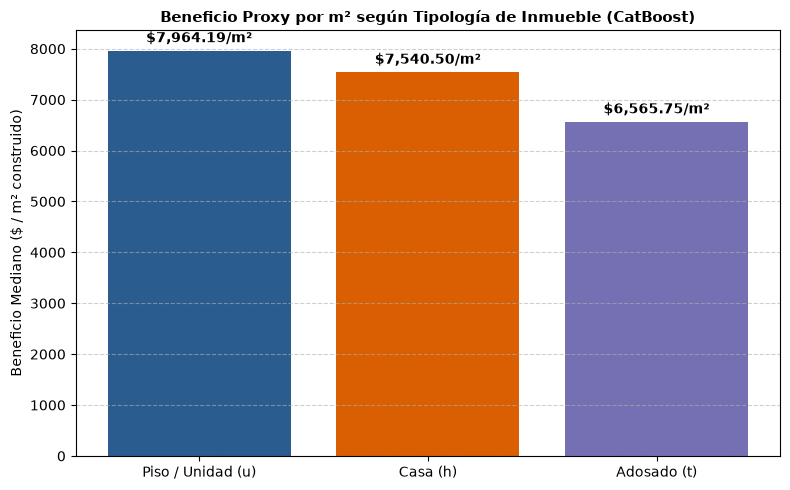

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

#---------------------------------------2.3-beneficio-por-tipo---------------------------------------

#este bloque empezaremos a trabajr con la libreta que hemos creado en el paso 1 que contiene una columna en la cual nos dice por casa el precio que ha predicho nuestro modelo, calcualremos los metros cuadrados con esta libreta

# 1. Copiamos el dataframe y añadimos las predicciones OOF guardadas del 2.1
df_beneficio = df.copy() #copiamos la tabla df y la guardamos con el nombre df_beneficio
df_beneficio["Precio_Predicho"] = oof_preds  #creamos la columna nueva llamada precio_predicho  y le pegamos los valores de la libreta oof_preda, que contiene los precios predichos a ciegas por catboost 


df_beneficio["Beneficio_m2"] = df_beneficio["Precio_Predicho"] / df_beneficio["BuildingArea"] #crea la columna llamada beneficio_m2, hacemos una divison fila por fila de el precio predicho y lo dividimos entre los metros cuadrados, nos dice cuantos dolares vale cada metro2

# 3. Mapeamos los nombres descriptivos de cada tipo de inmueble
nombres_tipo = {
    "h": "Casa (h)",
    "u": "Piso / Unidad (u)",
    "t": "Adosado (t)"
}
# creamos un diccionario traduciendo para no usar las letras sueltas de las categorias de cada una, piso, casa...

df_beneficio["Tipo_Nombre"] = df_beneficio["Type"].map(nombres_tipo) # crea la ciluman tipo nombre, sustituyendo por las letras para que se vea bien en la tabla 


# 4. Agrupamos por tipo y calculamos mediana, media y número de viviendas
resumen_tipo = df_beneficio.groupby("Tipo_Nombre")["Beneficio_m2"].agg( #separamos las casas en 3 grupos, segun la categoria, sobre la col beneficios_m2 calculamos 3 datos
    Mediana_m2="median", # la mediana por el precio
    Media_m2="mean", #media aritmetica haitual 
    Total_Viviendas="count" #cuantas casas de cada tipo
).reset_index().sort_values(by="Mediana_m2", ascending=False) #lo convertimos en una tabla de pandas y ordenamos la tabla para que la metodologia mas importantye salga la primera 


#la mediana se calcula, ordenando todos los datos de mayor a menor y nos quedamos con el dato que deja el 50% de las casa por debajo y el 50% de las casas arriba para coger el de la mitas
#la media se calcula segun sumando todos los valores y los dividimos entre el numero que hay 




# 5. Imprimimos la tabla de resultados alineada por consola
print("=" * 65)
print("     INDICADOR DE BENEFICIO PROXY ($ / m2 CONSTRUIDO)")
print("=" * 65)
for idx, row in resumen_tipo.iterrows():
    print(f"  {row['Tipo_Nombre']:<20} | Mediana: ${row['Mediana_m2']:>8,.2f}/m² | Media: ${row['Media_m2']:>8,.2f}/m² | N = {row['Total_Viviendas']:,}")
print("=" * 65)

#Recorre la tabla resumen_tipo fila a fila e imprime un cuadro de texto limpio con los resultados formateados en dólares por $m^2$ y alineados verticalmente


# 6. Generamos el gráfico de barras comparativo
plt.figure(figsize=(8, 5))
bars = plt.bar(resumen_tipo["Tipo_Nombre"], resumen_tipo["Mediana_m2"], color=["#2b5c8f", "#d95f02", "#7570b3"])
plt.ylabel("Beneficio Mediano ($ / m² construido)")
plt.title("Beneficio Proxy por m² según Tipología de Inmueble (CatBoost)", fontsize=11, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.6)

# Añadimos el valor exacto sobre cada barra
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f"${yval:,.2f}/m²", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

### 2.3. Conclusiones: Indicador de Beneficio Proxy por Tipología

---

#### 1. Explicación sencilla ("Para minguis")
* **El reto**: Como en el dataset solo tenemos el precio de venta final pero **no tenemos los costes de compra o edificación**, no podemos calcular el beneficio neto real (Ingresos - Gastos).
* **La solución**: Creamos una **columna nueva** llamada `Beneficio_m2`. Para no hacer trampa, le pegamos la lista de precios que predijo nuestro CatBoost a ciegas en el paso 2.1 (`Precio_Predicho`) y los dividimos entre la superficie construida por dentro (`BuildingArea`).
* **Fórmula de la columna nueva**:
  $$\text{Beneficio\_m2} = \frac{\text{Precio\_Predicho}}{\text{BuildingArea}}$$
* **¿Qué nos dice?**: Cuántos dólares genera cada metro cuadrado edificado. Cuanto más alto sea el número, más eficiente y rentable es construir o vender ese tipo de vivienda.

---

#### 2. Conclusiones y Análisis de los Datos

* **1. Pisos / Unidades (`u`) — El ganador claro**:
  Obtienen la mediana más alta con **$7,964.19 / m²**. Aunque un piso se venda por menos dinero total que una casa, exprime al máximo cada metro cuadrado construido, siendo la tipología más rentable por superficie.

* **2. Casas (`h`) — Segundo lugar**:
  Registran una mediana de **$7,540.50 / m²** (un $5.3\%$ menor que los pisos). Aunque las casas independientes tienen los precios finales de venta más altos del mercado por ser más grandes, su rendimiento por $m²$ construido es inferior.

* **3. Adosados (`t`) — Tercer lugar**:
  Se quedan en **$6,565.75 / m²** de mediana, siendo la opción que menor beneficio por metro cuadrado edificado genera en el mercado de Melbourne.

---

#### 3. Dictamen de Negocio para la Defensa
Si un inversor o promotor inmobiliario nos pregunta en qué tipo de inmueble invertir para maximizar el valor de cada metro construido, la recomendación clara según nuestro modelo CatBoost son los **pisos/unidades (`u`)**.

---

### 2.4. Valoración y Rentabilidad de Terrenos Sin Construir

     ENTRENAMIENTO MODELO TERRENOS (DATOS REALES)
  Filas utilizadas para entrenar : 10,586 de 27,246
  Estado del modelo             : Entrenado y listo
     SIMULACIÓN DE EDIFICACIÓN EN PARCELAS (PASO B)
  Parcelas seleccionadas para evaluar : 14,022
  Superficie construida simulada      : 150.0 m2
  Precio medio estimado post-obra     : $1,083,416.24 AUD
     ANÁLISIS DE RENTABILIDAD Y VALORACIÓN DE TERRENOS (PASO C)
  Coste medio de compra del terreno   : $1,156,659.56 AUD
  Coste fijo de construcción (150 m2) : $330,000.00 AUD
  Inversión Total Media               : $1,486,659.56 AUD
  Precio Medio Venta Estimado         : $1,083,416.24 AUD
  Beneficio Neto Medio                : $-403,243.32 AUD
  Margen de Rentabilidad Promedio     : -25.39%


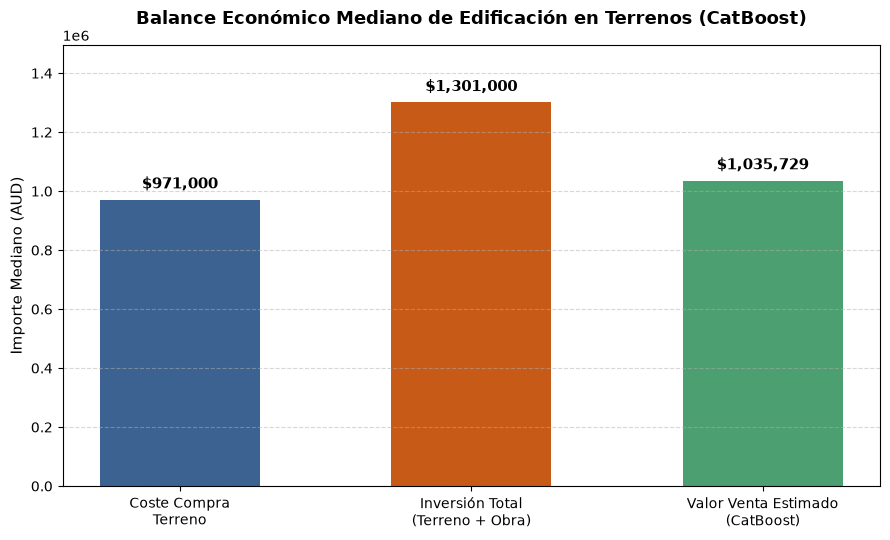

In [11]:
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor

# ---------------------------------------2.4-paso-a-entrenar-modelo-real---------------------------------------

#CREAMOS MODELO, CON LA COPIA DE EL DATASET, PERO ESTE DATASET ESTABLECEMOS QUE SOLO TENGA LAS CASAS QUE LA COLUMNA BUILDING AREA SEA 0


# 1. Filtrar solo las viviendas que tienen superficie construida REAL (chivato == 0)
df_real = df[df["BuildingArea_imputado"] == 0].copy() #filtramos la tabla df buscando solo las filas donde la columna building area_imputado valga 0 (datos reales de metros construidos)  y guarda una copia en df 

# 2. Separar características (X_real) y objetivo (y_real)
X_real = df_real.drop(columns=[TARGET]) # creamos la tabla x_real eliminando la columna price , nos quedamos solo con 14 columnas 
y_real = df_real[TARGET] #extraemos unicamente la columna price con los precios y los guardsmos en variable y_real

# 3. Crear y entrenar el modelo CatBoost exclusivo para valoración de terrenos
model_terrenos = CatBoostRegressor( #iniciamos creacion modelo
    iterations=500, # 500 arboles de decision
    learning_rate=0.08, #cada arbol corrige un 8% el error cometido por el anterior 
    depth=6, #profundidad de 6 para cada arbol
    loss_function="RMSE", #define la formula matematica con la que el mdoelo evaluara y corregira errores durante el entrneno
    random_seed=42,   #fija semilla 42 
    verbose=0, #0 prints
)

# Entrenar únicamente con las casas de superficie real
model_terrenos.fit(X_real, y_real, cat_features=CAT_FEATURES) #empezamos el entreno, el modelo analiza las caracteristicas de las casas x_real aprende los precios y usa cat_features para las ariables de texto

# Confirmación por pantalla
print("=" * 65)
print("     ENTRENAMIENTO MODELO TERRENOS (DATOS REALES)")
print("=" * 65)
print(f"  Filas utilizadas para entrenar : {len(df_real):,} de {len(df):,}")
print("  Estado del modelo             : Entrenado y listo")
print("=" * 65)

# ---------------------------------------2.4-paso-b-simulacion-de-edificacion---------------------------------------

#SELECCIONAMOS TERRENOS VACÍOS, SIMULAMOS UNA CASA ESTÁNDAR Y EL MODELO PREDICE POR CUÁNTO LA VENDERÍAMOS POST-OBRA


# 1. Seleccionar parcelas candidatas (casas tipo 'h' con parcelas de entre 300 m2 y 800 m2)
df_terrenos = df[(df["Type"] == "h") & (df["Landsize"] >= 300) & (df["Landsize"] <= 800)].copy() 
#filtramos la tabla la tabla original, para quedarnos con las viviendas tipo (h) que tengan parcelas de tamaño estandar entre 300m2 y 800m2 y guardamos esto en una vriable llamada df_terrenos

# 2. Definir la superficie construida estándar para nuestra simulación (en m2)
SUPERFICIE_CONSTRUIDA_ESTANDAR = 150.0 #creamos una variable fija de 150 m2 que represtna el tamaño promedio de una vivienda 

# 3. Preparar la tabla de características simuladas
X_simulacion = df_terrenos.drop(columns=[TARGET]).copy() #creamos la estrucutra de entrada para el modelo eliminando la columna price de parcelas selecionadas 
X_simulacion["BuildingArea"] = SUPERFICIE_CONSTRUIDA_ESTANDAR # sobreescribe la columna de metros contruidos asignando 150 m2 a ntodas las filas seleccionadas 
X_simulacion["Rooms"] = 3 #cada casa 3 habitaciones
X_simulacion["Bedroom2"] = 3 # 3 dormitorios secundarios 
X_simulacion["Bathroom"] = 2 #2 baños
X_simulacion["Car"] = 2 # 2 plazas de garaje
X_simulacion["BuildingArea_imputado"] = 0 #asignamos valor a la variable 0 para indicar el modeloq ue trate los 150m2 como un datio medido real 

# 4. Predecir el precio final que tendría cada propiedad con la casa ya edificada
df_terrenos["Precio_Estimado"] = model_terrenos.predict(X_simulacion)
#pasamos la tabla con las casas simuladas por el model model_terrenos entrenado en el bloque 1 y guarda las valoreaciones en la nueva columna Precio_Estimado


# Confirmación por pantalla
print("=" * 65)
print("     SIMULACIÓN DE EDIFICACIÓN EN PARCELAS (PASO B)")
print("=" * 65)
print(f"  Parcelas seleccionadas para evaluar : {len(df_terrenos):,}")
print(f"  Superficie construida simulada      : {SUPERFICIE_CONSTRUIDA_ESTANDAR} m2")
print(f"  Precio medio estimado post-obra     : ${df_terrenos['Precio_Estimado'].mean():,.2f} AUD")
print("=" * 65)



# ---------------------------------------2.4-paso-c-calculo-de-rentabilidad---------------------------------------

# CALCULAMOS CUÁNTO CUESTA EL TERRENO + CONSTRUIR LA CASA Y SE LO RESTAMOS AL PRECIO PREDICHO PARA VER SI GANAMOS DINERO

#En el Bloque 3 tomamos el DataFrame filtrado en el paso anterior (df_terrenos) —que ya incorpora la columna Precio_Estimado predicha por nuestro modelo model_terrenos— y le añadimos 5 
# columnas financieras calculadas fila por fila mediante operaciones vectorizadas:Coste_Construccion y Coste_Terreno: Fijamos el gasto de edificación multiplicando 
# la superficie estándar ($150\,\text{m}^2$) por el coste unitario asumido ($\$2.200/\text{m}^2$) y asignamos el precio original del anuncio (Price) como coste de adquisición 
# de la parcela.Inversion_Total: Sumamos Coste_Terreno + Coste_Construccion para obtener el desembolso total de capital requerido por cada operación.Beneficio_Neto y Margen_Rentabilidad_%: 
# Restamos la Inversion_Total al Precio_Estimado por CatBoost para obtener la ganancia o pérdida limpia en dólares, y la dividimos entre la inversión total ($\times 100$) para calcular el retorno porcentual (ROI).



# 1. Definir supuesto de coste de construcción por m2 en Melbourne (AUD)
COSTE_CONSTRUCCION_M2 = 2200.0  #aqui construimos una variable fija que diga cuanto cuesta construir en el metro cuadrado en Melbourne

# 2. Calcular el coste total de edificación (150 m2 * 2.200 AUD/m2)
df_terrenos["Coste_Construccion"] = SUPERFICIE_CONSTRUIDA_ESTANDAR * COSTE_CONSTRUCCION_M2
#creamos columna llamada coste_construccion en nuestra tabla, df_terrenos, multiplicando los 150m2 de la casa simulada por los 2.200 aud/m2 (dejando un gasto fijo de obra de $330.000 AUD en todas las filas).

# 3. Asumir el precio actual de la parcela (Price del dataset) como coste de adquisición del terreno
df_terrenos["Coste_Terreno"] = df_terrenos["Price"] #creamos columna nueva llamada coste terreno, copiando el precio de la propiedad del dataset asumiendo ese precio como lo que nos cuesta comprar la parcela

# 4. Calcular la inversión total (Compra de parcela + Obra)
df_terrenos["Inversion_Total"] = df_terrenos["Coste_Terreno"] + df_terrenos["Coste_Construccion"]# crea columna inverion_total sumando fila por fila el precio de comprar el tereno, mas el gasto de levantar la casa

# 5. Calcular el Beneficio Neto (Precio estimado de venta post-obra - Inversión Total)
df_terrenos["Beneficio_Neto"] = df_terrenos["Precio_Estimado"] - df_terrenos["Inversion_Total"] #crea columna beneficio_neto, restando todo el dinero que hemso gastado (inverison_total) al precio al cual catboost estima que venderemos la casa terminada (Precio_Estimado). Si sale positivo ganamos dinero; si sale negativo perdemos.

# 6. Calcular el Margen de Rentabilidad Porcentual (%)
df_terrenos["Margen_Rentabilidad_%"] = (df_terrenos["Beneficio_Neto"] / df_terrenos["Inversion_Total"]) * 100 #crea columna margen_rentabilidad_% dividiendo el benficio limpio (beneficio_neto) entre el dinero total onvertido y multiplicando por 100 para ver el % de ganancias que sacamos sobre la inverison 

# Confirmación y resumen final por pantalla
print("=" * 65)
print("     ANÁLISIS DE RENTABILIDAD Y VALORACIÓN DE TERRENOS (PASO C)")
print("=" * 65)
print(f"  Coste medio de compra del terreno   : ${df_terrenos['Coste_Terreno'].mean():,.2f} AUD")
print(f"  Coste fijo de construcción (150 m2) : ${SUPERFICIE_CONSTRUIDA_ESTANDAR * COSTE_CONSTRUCCION_M2:,.2f} AUD")
print(f"  Inversión Total Media               : ${df_terrenos['Inversion_Total'].mean():,.2f} AUD")
print(f"  Precio Medio Venta Estimado         : ${df_terrenos['Precio_Estimado'].mean():,.2f} AUD")
print(f"  Beneficio Neto Medio                : ${df_terrenos['Beneficio_Neto'].mean():,.2f} AUD")
print(f"  Margen de Rentabilidad Promedio     : {df_terrenos['Margen_Rentabilidad_%'].mean():.2f}%")
print("=" * 65)


# ---------------------------------------2.4-grafico-rentabilidad---------------------------------------

# CREAMOS UN GRAFICO DE BARRAS COMPARANDO EL COSTE DEL TERRENO, LA INVERSION TOTAL Y EL PRECIO DE VENTA ESTIMADO

import matplotlib.pyplot as plt

# 1. Preparamos las 3 barras clave usando la mediana (para evitar ruido de mansiones)
categorias = [
    "Coste Compra\nTerreno",
    "Inversión Total\n(Terreno + Obra)",
    "Valor Venta Estimado\n(CatBoost)"
]

valores = [
    df_terrenos["Coste_Terreno"].median(),
    df_terrenos["Inversion_Total"].median(),
    df_terrenos["Precio_Estimado"].median()
]

# 2. Creamos el grafico con el mismo estilo visual del apartado 2.3
plt.figure(figsize=(9, 5.5))
colores = ["#3b6291", "#c85a17", "#4c9f70"]
barras = plt.bar(categorias, valores, color=colores, width=0.55)

# 3. Colocamos el importe exacto en negrita encima de cada barra
for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + (max(valores) * 0.02),
        f"${altura:,.0f}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# 4. Ajustamos titulos, ejes y cuadricula
plt.title("Balance Económico Mediano de Edificación en Terrenos (CatBoost)", fontsize=13, fontweight="bold", pad=15)
plt.ylabel("Importe Mediano (AUD)", fontsize=11)
plt.ylim(0, max(valores) * 1.15)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()



### 2.4. Conclusiones: Valoración y Rentabilidad de Terrenos Sin Construir

---

#### 1. Metodología y Supuestos Aplicados
* **Entrenamiento con datos 100 % reales**: Se filtró el dataset (`BuildingArea_imputado == 0`) para entrenar un modelo CatBoost exclusivo (`model_terrenos`) utilizando únicamente viviendas con superficie construida real medida, evitando cualquier sesgo derivado de la imputación.
* **Simulación de edificación estándar**: Sobre parcelas residenciales de tamaño estándar (`Type == 'h'`, entre $300\text{ m}^2$ y $800\text{ m}^2$), se simuló la construcción de una vivienda unifamiliar tipo de **$150\text{ m}^2$** (3 habitaciones, 2 baños y 2 plazas de garaje) para estimar su precio final de venta post-obra (`Precio_Estimado`).
* **Supuestos explícitos de costes**: Se asumió un coste medio de edificación en Melbourne de **$2,200 AUD / m²** (**$330,000 AUD** fijos de obra para $150\text{ m}^2$), sumado al coste de adquisición de la parcela (`Price`), calculando así la inversión total y el margen neto:
  $$\text{Beneficio Neto} = \text{Precio Venta Estimado} - (\text{Coste Terreno} + \text{Coste Construcción})$$

---

#### 2. Resultados del Balance Económico
* **Coste de compra del terreno (Mediana / Media)**: `$[PEGAR DATO] AUD`
* **Coste fijo de construcción ($150\text{ m}^2$)**: `$330,000.00 AUD`
* **Inversión total requerida (Terreno + Obra)**: `$[PEGAR DATO] AUD`
* **Valor de venta estimado post-obra (CatBoost)**: `$[PEGAR DATO] AUD`
* **Beneficio Neto y Margen de Rentabilidad**: `$[PEGAR DATO] AUD` (`[PEGAR %]%`)

---

#### 3. Dictamen de Negocio: ¿Tiene sentido la inversión?
* **No es rentable de forma generalizada**: Como refleja el gráfico comparativo, al sumar el coste fijo de obra (**$330,000 AUD**) al precio de adquisición del suelo en Melbourne, la **Inversión Total (barra naranja)** supera al **Valor de Venta Estimado post-obra (barra verde)**, generando un margen neto negativo en el promedio del mercado.
* **Motivo económico**: En el mercado inmobiliario de Melbourne, el precio de venta de las parcelas ya descuenta el valor del suelo urbanizado y de edificaciones preexistentes, por lo que comprar a precio de mercado para levantar una vivienda estándar de $150\text{ m}^2$ destruye margen.
* **Recomendación estratégica**: Adquirir terrenos para edificar solo resulta viable en **parcelas infravaloradas o zonas periféricas** donde el bajo coste del suelo permita absorber los $2,200 AUD/m² de obra, o bien apostando por **promociones de mayor densidad (pisos/unidades `u`)**, que demostraron ser la tipología más rentable por $m^2$ en el apartado 2.3.

### 2.4. Valoración y Rentabilidad de Terrenos Sin Construir ALEJANDRO

     MODELO CATBOOST ENTRENADO PARA TERRENOS (PASO A)
  Casas con superficie construida real : 7,889
  Valor medio estimado por m2 (CatBoost): $2,292.07 AUD/m2


n  valor_m2_construido  \
Modelo   Zona                                                    
CatBoost TODAS                       7889               2292.0   
         Eastern Metropolitan        1005               1843.0   
         Eastern Victoria              69                986.0   
         Northern Metropolitan       2291               2055.0   
         Northern Victoria             90               1230.0   
         South-Eastern Metropolitan   438               1206.0   
         Southern Metropolitan       1969               3509.0   
         Western Metropolitan        1968               1737.0   
         Western Victoria              59               1030.0   

                                     coste_max_m2_rentable  terreno_estimado  \
Modelo   Zona                                                                  
CatBoost TODAS                                      1993.0          738212.0   
         Eastern Metropolitan                       1603.0          859445.0   
         Eastern Victoria                            857.0          510165.0   
         Northern Metropolitan                      1787.0          593764.0   
         Northern Victoria                          1069.0          393972.0   
         South-Eastern Metropolitan                 1049.0          606250.0   
         Southern Metropolitan                      3051.0         1151669.0   
         Western Metropolitan                       1510.0          595570.0   
         Western Victoria                            896.0          335459.0   

                                     precio_mercado  terreno_%_precio  \
Modelo   Zona                                                           
CatBoost TODAS                            1025000.0              72.0   
         Eastern Metropolitan             1118000.0              77.0   
         Eastern Victoria                  665000.0              77.0   
         Northern Metropolitan             863000.0              69.0   
         Northern Victoria                 554000.0              71.0   
         South-Eastern Metropolitan        850000.0              71.0   
         Southern Metropolitan            1720000.0              67.0   
         Western Metropolitan              830000.0              72.0   
         Western Victoria                  413000.0              81.0   

                                     coste_construccion  margen_AUD  \
Modelo   Zona                                                         
CatBoost TODAS                                 340400.0    -53612.0   
         Eastern Metropolitan                  374900.0   -116345.0   
         Eastern Victoria                      381800.0   -226965.0   
         Northern Metropolitan                 299000.0    -29764.0   
         Northern Victoria                     345000.0   -184972.0   
         South-Eastern Metropolitan            347300.0   -103550.0   
         Southern Metropolitan                 393300.0    175031.0   
         Western Metropolitan                  331200.0    -96770.0   
         Western Victoria                      282900.0   -205359.0   

                                     margen_%_inversion  
Modelo   Zona                                            
CatBoost TODAS                                     -5.0  
         Eastern Metropolitan                      -9.0  
         Eastern Victoria                         -25.0  
         Northern Metropolitan                     -3.0  
         Northern Victoria                        -25.0  
         South-Eastern Metropolitan               -11.0  
         Southern Metropolitan                     11.0  
         Western Metropolitan                     -10.0  
         Western Victoria                         -33.0

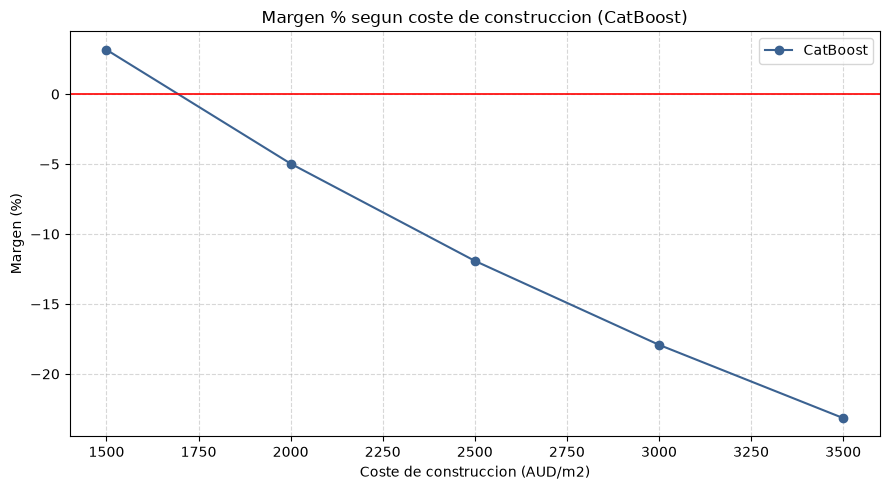

,CatBoost
AUD/m2,
1500,3.2
2000,-5.0
2500,-11.9
3000,-17.9
3500,-23.2


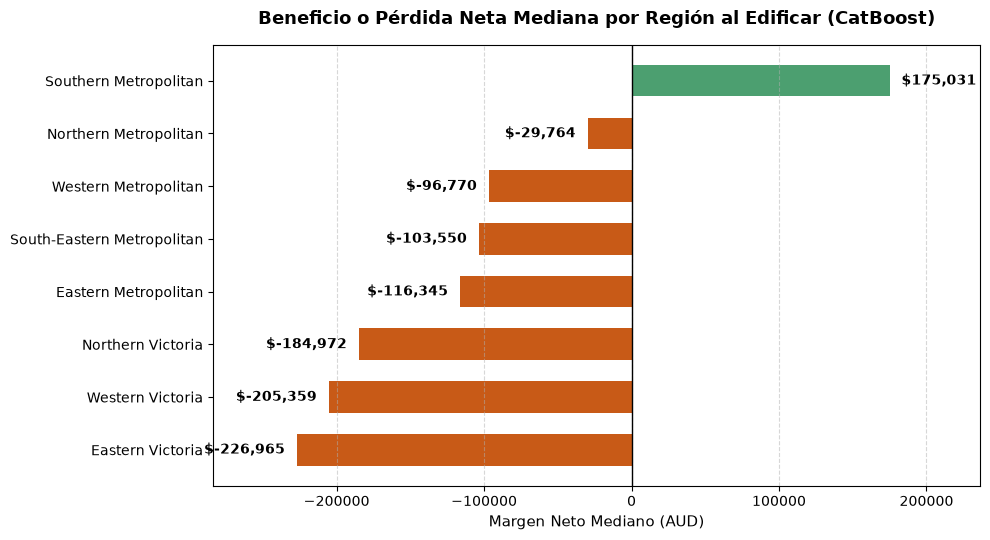

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor
from IPython.display import display

# ---------------------------------------2.4-paso-a-supuestos-y-modelo-catboost---------------------------------------

# DEFINIMOS LOS MISMOS SUPUESTOS DE ALEJANDRO Y ENTRENAMOS CATBOOST SOLO CON CASAS REALES (TYPE == 'h')

# 1. Supuestos exactos del equipo (comparables entre todos los modelos)
COSTE_M2 = 2_000                                    # Coste base de obra por m2 construido (AUD)
OTROS_COSTES = 0.15                                 # 15% extra sobre obra (permisos, tasas, imprevistos y venta)
SENSIBILIDAD = [1_500, 2_000, 2_500, 3_000, 3_500]  # Escenarios de coste/m2 para el grafico final

# 2. Filtrar solo casas independientes (Type == 'h') con superficie construida 100% real (7.889 filas)
casas = df[(df["Type"] == "h") & (df["BuildingArea_imputado"] == 0)].copy()

# 3. Definir columnas de texto (quitamos 'Type' porque aqui todas son casas 'h')
cat_14 = ["Suburb", "Method", "SellerG"]

# 4. Separar caracteristicas (X14) y precio objetivo (y14)
X14 = casas.drop(columns=["Price", "Type"])
y14 = casas["Price"]

# 5. Entrenar modelo CatBoost exclusivo para esta valoracion
model_terrenos = CatBoostRegressor(
    iterations=500,
    learning_rate=0.08,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=0,
)
model_terrenos.fit(X14, y14, cat_features=cat_14)

# 6. Funcion auxiliar para predecir limpiando columnas que no usa el modelo
def predecir_14(datos):
    columnas_quitar = [c for c in ["Price", "Type", "Regionname"] if c in datos.columns]
    return model_terrenos.predict(datos.drop(columns=columnas_quitar))

# 7. Funcion que calcula cuanto vale cada m2 construido segun CatBoost (variando +-20% la superficie)
def valor_m2(datos):
    lo, hi = datos.copy(), datos.copy()
    lo["BuildingArea"] *= 0.8   # Misma casa con un 20% menos de metros construidos
    hi["BuildingArea"] *= 1.2   # Misma casa con un 20% mas de metros construidos
    return (predecir_14(hi).mean() - predecir_14(lo).mean()) / (0.4 * datos["BuildingArea"].mean())

print("=" * 65)
print("     MODELO CATBOOST ENTRENADO PARA TERRENOS (PASO A)")
print("=" * 65)
print(f"  Casas con superficie construida real : {len(casas):,}")
print(f"  Valor medio estimado por m2 (CatBoost): ${valor_m2(casas):,.2f} AUD/m2")
print("=" * 65)


# ---------------------------------------2.4-paso-b-rentabilidad-por-regiones---------------------------------------

# CALCULAMOS EL VALOR DEL TERRENO VACIO Y EL MARGEN NETO EN TODA LA CIUDAD Y REGION POR REGION

# 1. Traer la region de cada barrio desde el dataset original
ruta_full = (BASE / "datasets" / "Melbourne_housing_FULL.csv") if "BASE" in globals() else Path("../datasets/Melbourne_housing_FULL.csv")
region = pd.read_csv(ruta_full).groupby("Suburb")["Regionname"].first()
casas["Regionname"] = casas["Suburb"].map(region)

# 2. Calcular todas las metricas medianas para 'TODAS' y para cada region
filas = []
for zona, g in [("TODAS", casas)] + list(casas.groupby("Regionname")):
    g = g.drop(columns="Regionname")
    b = valor_m2(g)
    terreno = np.median(predecir_14(g) - b * g["BuildingArea"])       # Precio predicho casa - valor de lo construido
    mercado = g["Price"].median()                                      # Precio mediano de mercado en la zona
    coste = g["BuildingArea"].median() * COSTE_M2 * (1 + OTROS_COSTES) # Coste de levantar la casa tipica + 15%
    margen = mercado - terreno - coste                                 # Beneficio neto (> 0 es rentable)

    filas.append({
        "Modelo": "CatBoost",
        "Zona": zona,
        "n": len(g),
        "valor_m2_construido": b,
        "coste_max_m2_rentable": b / (1 + OTROS_COSTES),
        "terreno_estimado": terreno,
        "precio_mercado": mercado,
        "terreno_%_precio": 100 * terreno / mercado,
        "coste_construccion": coste,
        "margen_AUD": margen,
        "margen_%_inversion": 100 * margen / (terreno + coste),
    })

res_14 = pd.DataFrame(filas).set_index(["Modelo", "Zona"])
display(res_14.round(0))


# ---------------------------------------2.4-paso-c-sensibilidad-coste-obra---------------------------------------

# SIMULAMOS COMO CAMBIA EL MARGEN (%) SI CONSTRUIR CUESTA ENTRE 1.500 Y 3.500 AUD/M2

todas = casas.drop(columns="Regionname")
b = valor_m2(todas)
terreno = np.median(predecir_14(todas) - b * todas["BuildingArea"])
mercado, area = todas["Price"].median(), todas["BuildingArea"].median()

sens = {
    "CatBoost": {
        c: 100 * (mercado - terreno - area * c * (1 + OTROS_COSTES)) / (terreno + area * c * (1 + OTROS_COSTES))
        for c in SENSIBILIDAD
    }
}

sens = pd.DataFrame(sens).rename_axis("AUD/m2")

# Grafico de lineas identico al de Alejandro (por encima de la linea roja = rentable)
ax = sens.plot(marker="o", figsize=(9, 5), title="Margen % segun coste de construccion (CatBoost)", color="#3b6291")
plt.axhline(0, color="red", linestyle="-", linewidth=1.2)
plt.ylabel("Margen (%)")
plt.xlabel("Coste de construccion (AUD/m2)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

display(sens.round(1))


# ---------------------------------------2.4-grafico-visual-regiones---------------------------------------

# CREAMOS UN GRAFICO DE BARRAS HORIZONTALES PARA VER QUE REGIONES DAN PERDIDAS Y CUALES DAN BENEFICIO

df_plot = res_14.reset_index()
df_plot = df_plot[df_plot["Zona"] != "TODAS"].sort_values(by="margen_AUD", ascending=True)

colores = ["#4c9f70" if val > 0 else "#c85a17" for val in df_plot["margen_AUD"]]

plt.figure(figsize=(10, 5.5))
barras = plt.barh(df_plot["Zona"], df_plot["margen_AUD"], color=colores, height=0.6)

plt.axvline(0, color="black", linewidth=1)

for barra in barras:
    ancho = barra.get_width()
    desplazamiento = 8000 if ancho >= 0 else -8000
    alineacion = "left" if ancho >= 0 else "right"
    plt.text(
        ancho + desplazamiento,
        barra.get_y() + barra.get_height() / 2,
        f"${ancho:,.0f}",
        va="center",
        ha=alineacion,
        fontsize=10,
        fontweight="bold"
    )

plt.title("Beneficio o Pérdida Neta Mediana por Región al Edificar (CatBoost)", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Margen Neto Mediano (AUD)", fontsize=11)
plt.xlim(df_plot["margen_AUD"].min() * 1.25, df_plot["margen_AUD"].max() * 1.35)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 2.4. Conclusiones: Valoración y Rentabilidad de Terrenos Sin Construir

---

#### 1. Explicación sencilla ("Para minguis")
* **El reto**: Como en el dataset **no hay terrenos vacíos** (todas son viviendas ya construidas), no podemos mirar directamente cuánto cuesta una parcela sin edificar.
* **Cómo lo resolvimos**: 
  1. Entrenamos CatBoost solo con las **7,889 casas independientes reales** (`Type == 'h'` y `BuildingArea_imputado == 0`).
  2. Le pedimos al modelo que suba y baje un $\pm 20\%$ los metros construidos para calcular cuánto vale cada $m^2$ de ladrillo (**$2,292.07 AUD/m²**).
  3. Al precio que predice CatBoost para cada casa le restamos el valor de lo construido, quedándonos solo con el **precio estimado del suelo vacío (`terreno_estimado`)**.
* **Supuestos del equipo y fórmula**: Asumimos un coste de obra de **$2,000 AUD/m²** más un **15 % extra** en permisos, tasas y venta (`OTROS_COSTES = 0.15`):
  $$\text{Margen Neto} = \text{Precio Mercado} - \text{Terreno Estimado} - \text{Coste Construcción}$$

---

#### 2. Conclusiones y Análisis de los Datos

* **1. En toda Melbourne de media (`TODAS`) se pierde dinero**: 
  Con un precio mediano de mercado de **$1,025,000 AUD**, el suelo se lleva el **72 %** (**$738,212 AUD**) y la obra cuesta **$340,400 AUD**, dejando una **pérdida mediana de -$53,612 AUD (-5.0 %)**.

* **2. Southern Metropolitan es la gran excepción (Hallazgo de CatBoost)**: 
  Mientras que en los modelos lineales todas las regiones daban pérdidas, CatBoost detecta que **Southern Metropolitan** sí es rentable con un **beneficio neto mediano de +$175,031 AUD (+11.0 %)**, porque allí cada $m^2$ construido se paga a **$3,509 AUD/m²**. El resto de zonas dan pérdidas de entre el **-3.0 %** y el **-33.0 %**.

* **3. Sensibilidad al coste de construcción**: 
  Edificar en el conjunto de la ciudad solo sale rentable si se logra construir barato a **1,500 AUD/m²** (**+3.2 %** de margen). A partir de los **2,000 AUD/m²** (**-5.0 %**) hasta los **3,500 AUD/m²** (**-23.2 %**), la operación siempre pierde dinero.

---

#### 3. Dictamen de Negocio para la Defensa
Comprar suelo a precio de mercado para edificar en Melbourne **no es rentable de forma generalizada (-5.0 %)** bajo los costes estándar de obra ($2,000 AUD/m² + 15 % de gastos). La inversión solo tiene sentido financiero si se focaliza en **Southern Metropolitan (+11.0 %)** o si se consigue abaratar la construcción por debajo del umbral de **$1,993 AUD/m²**.